# Label-free, non-destructive readout of organ-on-a-chip experiments: a walkthrough

**AI4S Open Innovation: AI for Life Science** · Category: **End-to-End System** · Team **tmgf** (tiagomgfernandes)
· [Code](https://github.com/tmgf-lab/CCP002-KAGGLE-019-PUB_AI4S_AI-Organ-on-a-Chip) · Video: see the Kaggle Writeup<!--YOUTUBE-->

The standard Cell Painting stain protocol requires fixation, which makes it an endpoint assay, so
each sample gives one snapshot; this project asks whether the same information can be read from **bright-field images alone**, through four questions:

| | Question | Input → output |
|---|---|---|
| **Q1** | Virtual staining | 3 bright-field z-planes → 5 Cell Painting stains (DNA, ER, RNA, AGP, Mito) |
| **Q2** | Toxicity and drug response | per-well image features → toxic? viability? changed by the drug? |
| **Q3** | Single cells | real vs virtual stains → segmented cells, per-cell features, cell states |
| **Q4** | Chip quality control | photo of a real organ-on-a-chip → good / bad chip |

Every question is answered the same way: a **guided search over analysis paths** (processing → model → exploration →
evaluation). Each path is scored on **25% → 50% → 100%** of the data; the worse half is stopped at each checkpoint, options
that fail 4 times are excluded, repeats are skipped, and test data is used once at the end.

**Sample or full (`MODE`, first code cell).** `MODE = "sample"` (default) runs every step on a small share of the data, in minutes
on a CPU; `MODE = "full"` runs the same commands on all the data with the study's budgets (all plates, the full Q1 tree, all 16 Q2
searches), which needs a GPU and many hours. The two modes run the same code, so a passing sample run tests the steps of the full
run. Steps that are not run here (the Q1 final stage, Q3 and Q4 searches, U2OS) use the commands of the last section.

**How this notebook works.** Each section first runs a **small real version** of the same command used for the full results
(fewer paths, less data, so it finishes in minutes), then loads the **saved full-scale results** from `results/`.
Small runs show *how* the system works; their numbers are not the reported results.

Runtime: under 20 minutes on a CPU (9 min on a 12-core laptop; Kaggle CPU sessions have 4 cores), a few minutes on a GPU. Internet is needed (data streams from the public
Cell Painting Gallery, CC0).

## 0. Setup

In [1]:
import os, sys, json, subprocess, glob
from pathlib import Path

# MODE "sample" (default): every step runs on a small share of the data, in minutes on a CPU.
# MODE "full": the same commands on all the data with the study's budgets (needs a GPU and many hours; set VCP_MODE=full).
MODE = os.environ.get("VCP_MODE", "sample")
assert MODE in ("sample", "full"), MODE

# Inside the repository: use it. On Kaggle or elsewhere: clone it (the data and weights are downloaded below).
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "sweep" / "engine.py").exists()), None)
CLONED = ROOT is None  # e.g. on Kaggle: clone the repository and install what the image lacks
if ROOT is None:
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/tmgf-lab/CCP002-KAGGLE-019-PUB_AI4S_AI-Organ-on-a-Chip", "vcp"], check=True)
    ROOT = Path("vcp").resolve()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch", "optuna", "cellpose<4",
                    "mahotas", "imagecodecs", "umap-learn", "leidenalg"], check=False)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# Check that this kernel has the packages of requirements.txt (the web-demo package gradio is not needed here).
import importlib.metadata as _md, re as _re
_need = [_re.split(r"[=<>~!\s#;]", l.strip())[0] for l in open(ROOT / "requirements.txt")
         if l.strip() and not l.lstrip().startswith("#")]
_missing = []
for _n in _need:
    try:
        _md.version(_n)
    except _md.PackageNotFoundError:
        _missing.append(_n)
_missing = [n for n in _missing if n.lower() != "gradio"]
if _missing and not CLONED:
    # Install the missing packages into THIS kernel's Python (exact versions of requirements.txt; in an existing environment this can
    # change versions already installed there, so a dedicated environment is recommended, see the README).
    print("Installing missing packages into", sys.executable, ":", ", ".join(_missing))
    !{sys.executable} -m pip install -q -r requirements.txt
    _still = []
    for _n in _missing:
        try:
            _md.version(_n)
        except _md.PackageNotFoundError:
            _still.append(_n)
    if _still:
        raise RuntimeError("Could not install: " + ", ".join(_still) + ". See the pip messages above, or set up the environment of the "
                           "README (python3.11 -m venv .venv; pip install -r requirements.txt) and select it as the kernel.")
    print("Installed. If a cell below fails on an import, restart the kernel and run the notebook again.")
elif _missing:
    print("Warning: packages not found (installed above where possible):", ", ".join(_missing))
os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]  # `!python` = this kernel
os.environ.update(PYTHONWARNINGS="ignore", TF_CPP_MIN_LOG_LEVEL="3", VCP_VERBOSE_PATHS="1", PYTHONNOUSERSITE="1")
import tempfile
WORK = Path(os.environ.get("VCP_WORK", Path(tempfile.gettempdir()) / "vcp_walkthrough"))  # local disk: search databases need file locks
WORK.mkdir(exist_ok=True)

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, display
GPU = torch.cuda.is_available()
print("mode:", MODE, "| repository:", ROOT, "| work folder:", WORK, "| device:", "GPU" if GPU else "CPU")

mode: sample | repository: /mnt/nas/tmgf-lab/coding-competitions/CCP002-kaggle-019_ai-4-s-open-innovation-artificial-intelligence-for-life-scien/working/submission/repo | work folder: /tmp/vcp_walkthrough | device: GPU


In [2]:
# The final Q1 model (2 seeds, 121 MB each) is not in git: download once and verify the checksums.
from weights import winner_json
WINNER = winner_json()
print(open(WINNER).read()[:400])

{
 "config": "final/t038",
 "run_dirs": [
  "/mnt/nas/tmgf-lab/coding-competitions/CCP002-kaggle-019_ai-4-s-open-innovation-artificial-intelligence-for-life-scien/working/submission/repo/runs/winner/seed1",
  "/mnt/nas/tmgf-lab/coding-competitions/CCP002-kaggle-019_ai-4-s-open-innovation-artificial-intelligence-for-life-scien/working/submission/repo/runs/winner/seed3"
 ],
 "inference": "seed_ensem


## 1. Data: public, streamed, split by compound

[CPJUMP1](https://github.com/jump-cellpainting/2024_Chandrasekaran_NatureMethods_CPJUMP1) (JUMP Cell Painting pilot,
Cell Painting Gallery `cpg0000`, CC0): 384-well plates of A549 cells treated with 302 compounds for 48 h, imaged with 5
fluorescent stains and 3 bright-field planes. Compounds are split **by compound** (70/10/20 by a fixed hash), so
"held-out" compounds were never seen in training, on any plate.

Below, `download.py` streams a **sample** of the training plate (8 wells per split, one field per well) for the small Q1 run.
The full study used the 1,152 fields of the training plate (888 training and DMSO, 96 validation, 168 held-out compounds) and
1,536 test fields (2 plates never used for Q1 training).

In [3]:
if MODE == "sample":   # 8 wells per split of the training plate, one field each
    !VCP_DATA={WORK}/data python download.py --sample 8 --plates BR00117015 --sites 1
else:                  # every field of the training and test plates in config.py (about 13 GB)
    !VCP_DATA={WORK}/data python download.py

split
train      232
control     64
test        56
val         32
BR00117015: sites [1], 32 wells
  BR00117015: 0 sites already done, 32 to fetch
  BR00117015: 32/32 sites


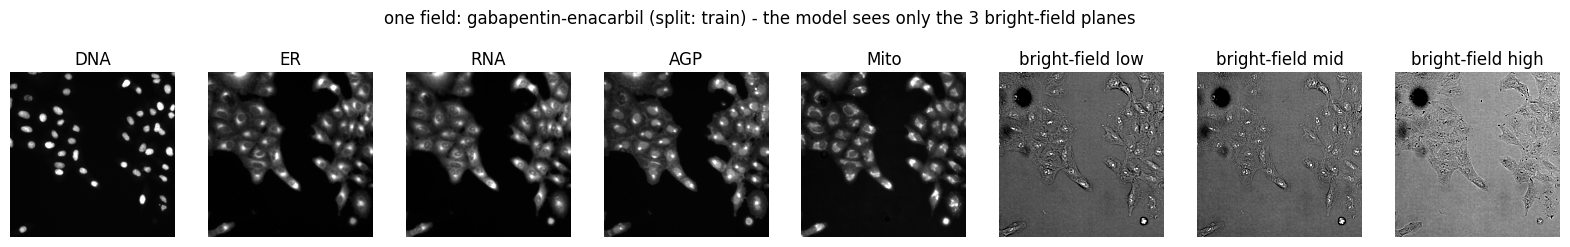

split
train      8
control    8
test       8
val        8
Name: count, dtype: int64

In [4]:
import config as C, importlib
os.environ["VCP_DATA"] = str(WORK / "data"); importlib.reload(C)
import data as D; importlib.reload(D)
arr, idx = D.load_plate("BR00117015")
lo, hi = D.norm_params("BR00117015")
x = D.normalise(np.asarray(arr[0]), lo, hi)
names = ["DNA", "ER", "RNA", "AGP", "Mito", "bright-field low", "bright-field mid", "bright-field high"]
fig, ax = plt.subplots(1, 8, figsize=(20, 3))
for c in range(8):
    ax[c].imshow(x[c, 100:400, 100:400], cmap="gray", vmin=np.percentile(x[c], 1), vmax=np.percentile(x[c], 99.7))
    ax[c].set_title(names[c]); ax[c].axis("off")
plt.suptitle(f"one field: {idx.pert_iname[0]} (split: {idx.split[0]}) - the model sees only the 3 bright-field planes"); plt.show()
idx.split.value_counts()

## 2. Q1 virtual staining: the guided path search

A path is `data → processing → model → exploration` (U-Net width, depth, attention, up-sampling). The full tree
(`sweep/configs/q1_translation.yaml`) was searched on 2 Kaggle T4 GPUs. Here the **same code** runs on a small demo tree
(`sweep/configs/q1_demo.yaml`), short training (and even shorter on a CPU). Watch each path go 25% → 50% → 100% and the worse
half stop.

In [5]:
print(open("sweep/configs/q1_demo.yaml").read())

# Q1 demo tree for the video: same engine and code as q1_translation.yaml, a smaller tree and short training so that a
# full search (25% -> 50% -> 100% checkpoints, successive halving) finishes in minutes on a 6 GB laptop GPU.
tree:
  data:          [brightfield_a549]
  transform:     [plate_scaling, image_scaling+augmentation]
  model:         [unet]
  exploration:
    width:       [16, 32]
    depth:       [4]
    attention:   [off, on]
    upsampling:  [transpose, bilinear]

search:
  method: bayesian_tpe
  early_stopping: successive_halving
  paths_to_try: 6
  parallel: 1
  time_limit_hours: 0.25
  checkpoints:
    - {data: 25%,  steps: 60}
    - {data: 50%,  steps: 60}
    - {data: 100%, steps: 120}



In [6]:
os.environ.update(VCP_RUNS=str(WORK / "q1"), VCP_Q1_CONFIG="q1_demo.yaml" if MODE == "sample" else "q1_translation.yaml")
if MODE == "sample":
    smoke, trials = ("", 6) if GPU else ("--smoke", 4)   # CPU: 4 paths, 10 training steps per checkpoint: mechanics only
else:
    smoke, trials = "", 40   # the study's tree and budget (40 paths; the study used 2 GPUs for 6.5 h)
!python -m sweep.q1_translation init
!python -m sweep.q1_translation search --gpu 0 --trials {trials} {smoke}
!python show.py q1search {WORK}/q1

[I 2026-10-10 16:29:33,020] A new study created in RDB with name: q1
study ready: 1 trial(s) queued
[I 2026-10-10 16:29:35,505] Using an existing study with `study_name='q1'` instead of creating a new one.
trial 0: brightfield_a549 -> plate_scaling -> unet -> width 32, depth 4, attention off, transpose -> pixel_r
    phase 1: 25% data, step 60: val r 0.8208 train r 0.8413 (0.3 min)
    phase 2: 50% data, step 120: val r 0.8513 train r 0.8554 (0.5 min)
    phase 3: 100% data, step 240: val r 0.8594 train r 0.8641 (1.0 min)
    -> completed: validation r 0.8594
trial 1: brightfield_a549 -> plate_scaling -> unet -> width 32, depth 4, attention off, bilinear -> pixel_r
    phase 1: 25% data, step 60: val r 0.8370 train r 0.8487 (0.3 min)
    phase 2: 50% data, step 120: val r 0.8628 train r 0.8621 (0.5 min)
    phase 3: 100% data, step 240: val r 0.8902 train r 0.8925 (1.1 min)
    -> completed: validation r 0.8902
trial 2: brightfield_a549 -> image_scaling+augmentation -> unet -> width 16

**Full-scale search** (A549 only; 9 early paths that mixed U2OS data into training are excluded, because datasets are
separate studies): the winner was a U-Net of width 64 with bilinear up-sampling. A final stage retrained the best paths with
several seeds and chose the inference mode (seed ensemble + test-time augmentation) on validation fields.

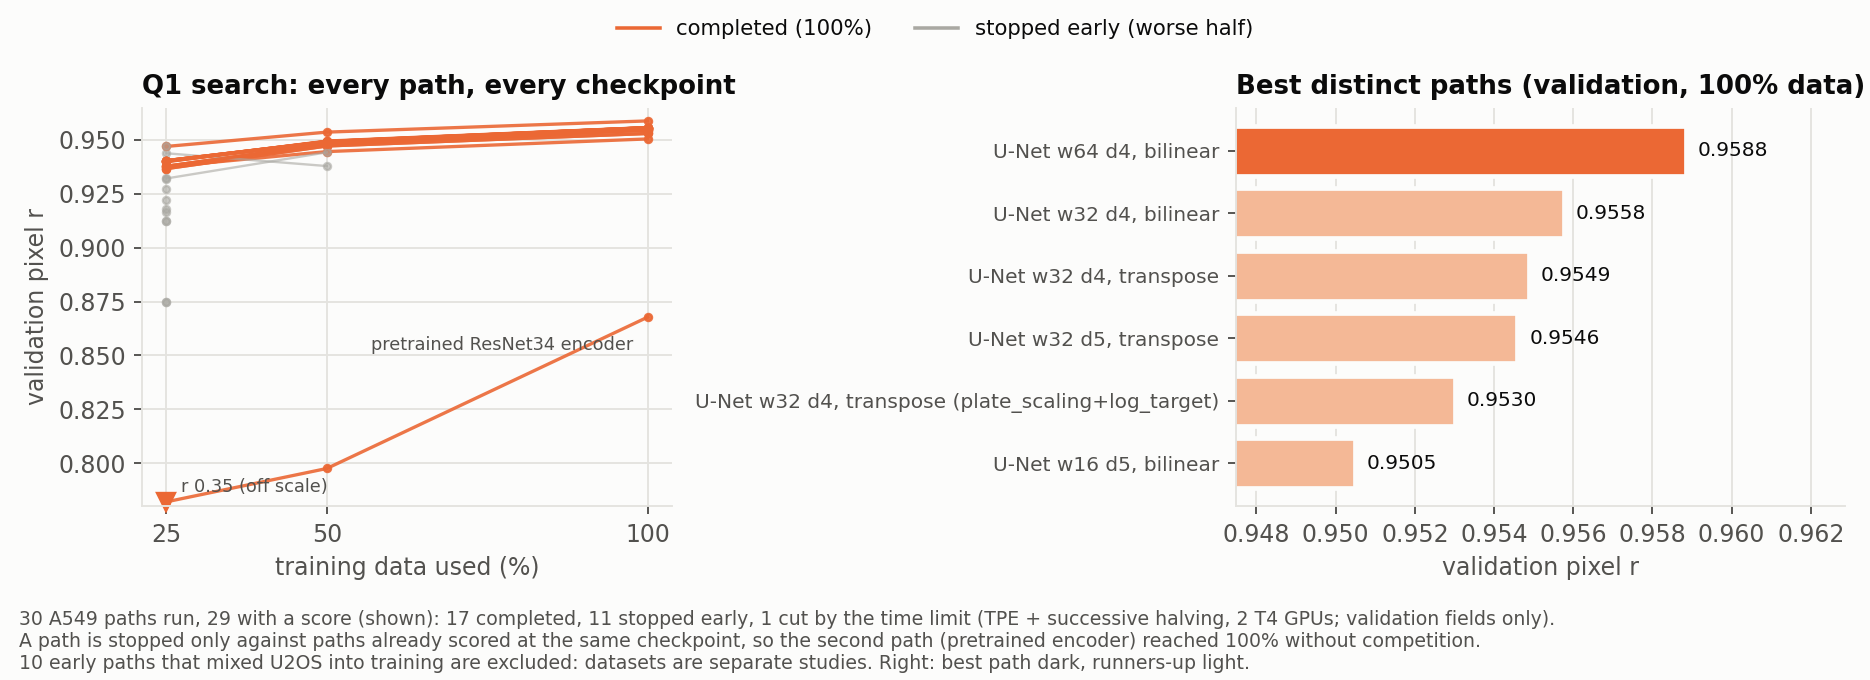

,group,config,mean,std,count
0,final,t038,0.9584,0.0003,2
1,variants,t038_brightfield_a549_2plates_none,0.9566,0.0036,2
2,final,t031,0.9555,0.0002,3
3,baseline,baseline,0.9553,0.0002,3
4,final,t011,0.9544,0.0002,3
5,variants,t038_brightfield_a549_focus_qc,0.9537,NaN,1
6,variants,t038_brightfield_a549_2plates_focus_qc,0.9427,NaN,1


In [7]:
display(Image("figures/fig_q1_search.png", width=1000))
pd.read_csv("results/a549/q1_final/final_summary.csv").round(4)

## 3. Q1 live: the final model on plates and compounds it never saw

Fields are streamed one by one from the archive (8 TIFFs each). The model sees only the bright-field planes; real stains are
shown for comparison. On a CPU the 2-seed ensemble is used; on a GPU also test-time augmentation (the validated mode).

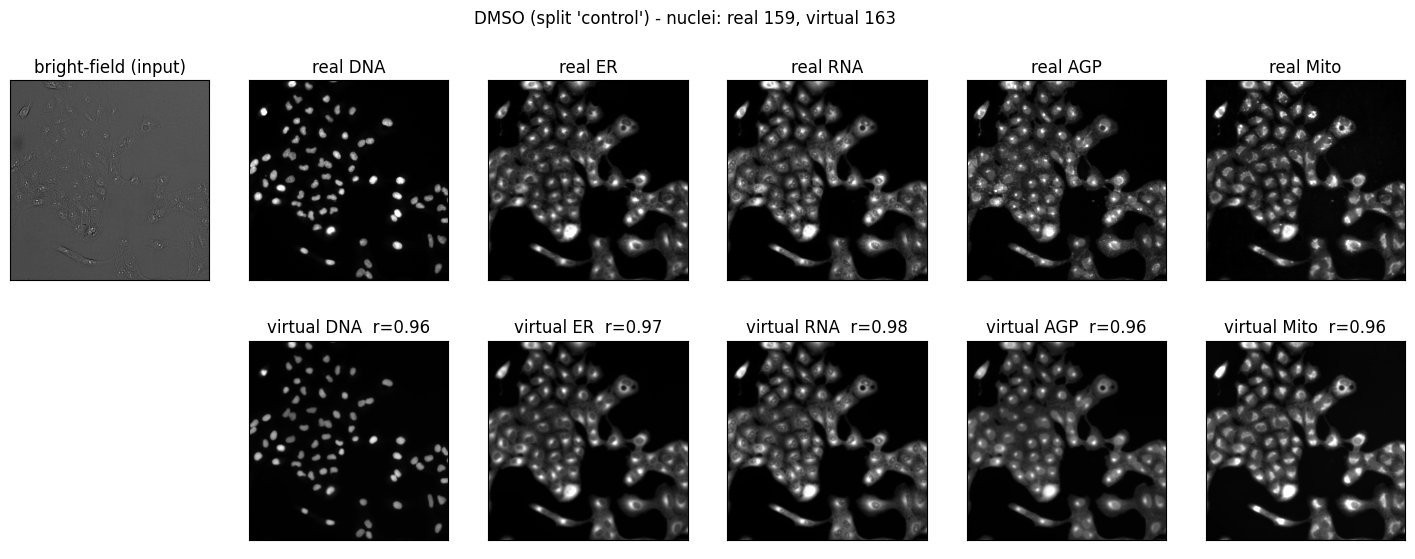

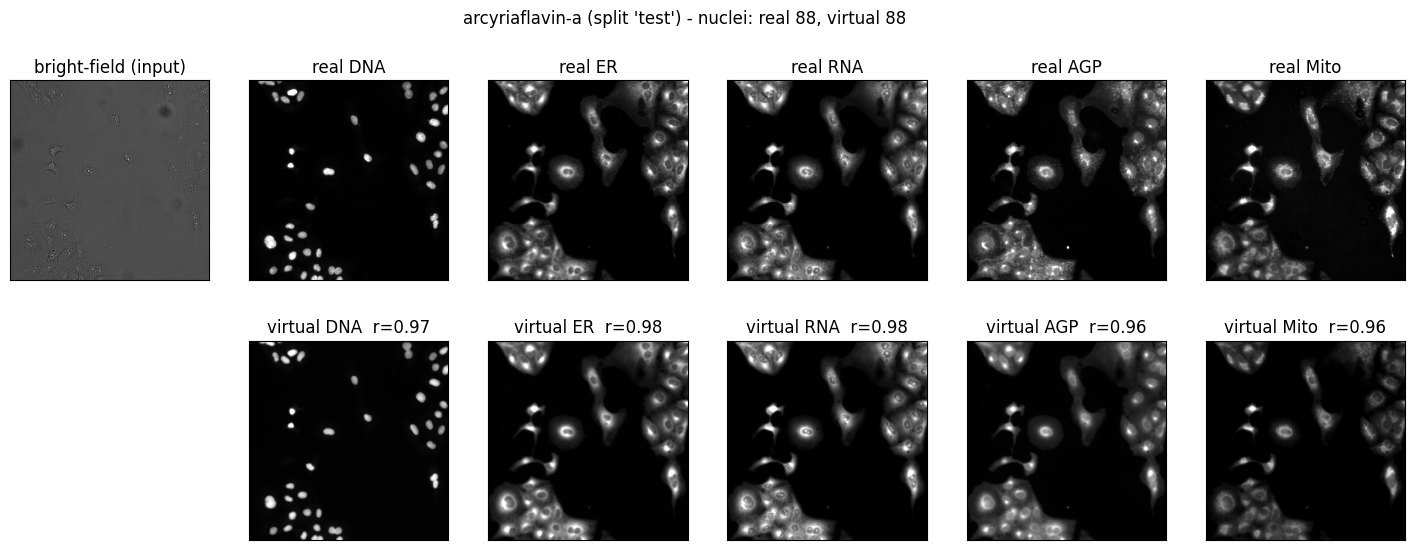

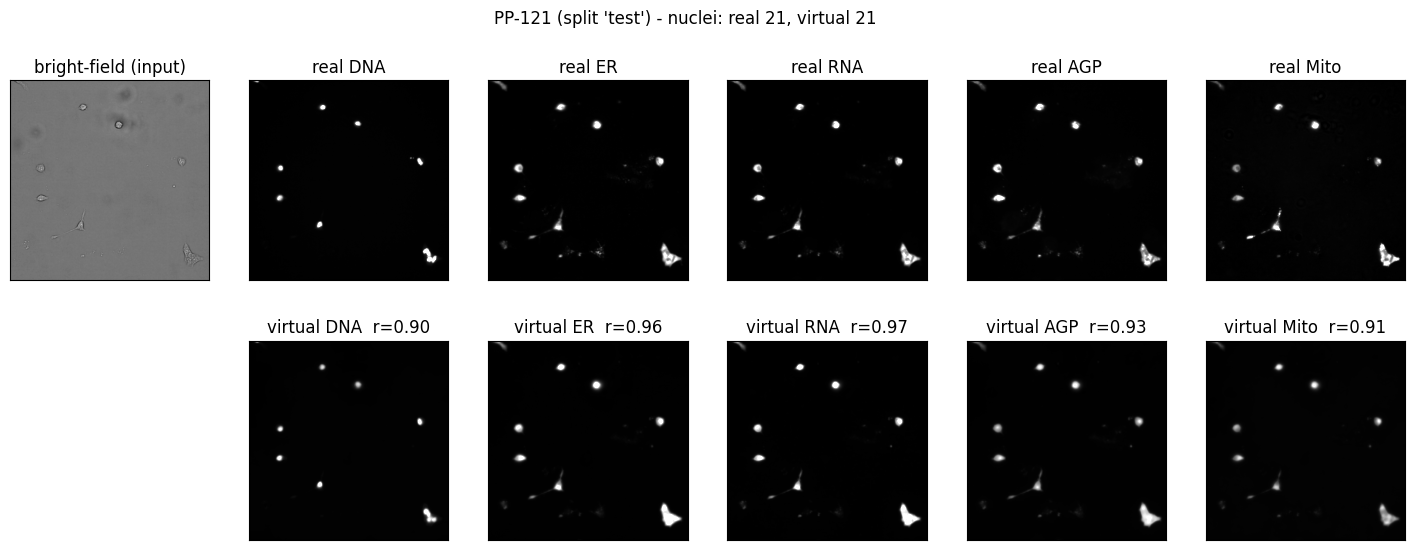

In [8]:
import io
from download import build_wells, fetch, load_site
from evaluate import nuclei
os.environ.pop("VCP_DATA"); importlib.reload(C); importlib.reload(D)
w = json.load(open(WINNER))
MODELS = [D.load_model(Path(d), dev="cuda" if GPU else "cpu") for d in w["run_dirs"]]
CFG, DEV = MODELS[0][1], ("cuda" if GPU else "cpu")
NORM = json.load(open("runs/winner/norm.json"))
wells = build_wells()
PLATE = "BR00117017"
LD = pd.read_csv(io.BytesIO(fetch(f"{C.S3}/{C.PILOT}/load_data_csv/{C.BATCH}/{PLATE}/load_data.csv")))
TGT = ["DNA", "ER", "RNA", "AGP", "Mito"]

def field(well, site=1):
    row = LD[(LD.Metadata_Well == well) & (LD.Metadata_Site == site)].iloc[0]
    n = NORM[PLATE]; lo_, hi_ = np.array(n["lo"], np.float32)[:, None, None], np.array(n["hi"], np.float32)[:, None, None]
    x = (load_site(row).astype(np.float32) - lo_) / (hi_ - lo_)
    v = D.predict_multi([m for m, _ in MODELS], CFG, x, DEV, GPU)
    return x[:5], v, x[6]

def show(compound):
    info = wells[wells.pert_iname == compound].iloc[0]
    real, virt, bf = field(info.well)
    r = [np.corrcoef(real[c].ravel(), virt[c].ravel())[0, 1] for c in range(5)]
    fig, ax = plt.subplots(2, 6, figsize=(18, 6.2)); crop = slice(100, 440)
    ax[0, 0].imshow(bf[crop, crop], cmap="gray"); ax[0, 0].set_title("bright-field (input)"); ax[1, 0].axis("off")
    for c in range(5):
        vmin, vmax = np.percentile(real[c][crop, crop], [1, 99.7])
        ax[0, c + 1].imshow(real[c][crop, crop], cmap="gray", vmin=vmin, vmax=vmax); ax[0, c + 1].set_title(f"real {TGT[c]}")
        ax[1, c + 1].imshow(virt[c][crop, crop], cmap="gray", vmin=vmin, vmax=vmax); ax[1, c + 1].set_title(f"virtual {TGT[c]}  r={r[c]:.2f}")
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    plt.suptitle(f"{compound} (split '{info.split}') - nuclei: real {nuclei(real[0])[0]}, virtual {nuclei(virt[0])[0]}"); plt.show()
    return real, virt

FIELDS = {c: show(c) for c in ["DMSO", "arcyriaflavin-a", "PP-121"]}  # control, held-out phenotype, held-out cytotoxic

**Full test result** (2 unseen plates, 1,536 fields, test plates used once): pixel correlation per stain for held-out
compounds, nuclei per well (agreement statistics), and *phenotypic activity*: whether a compound's image profile retrieves its
replicate on the other plate (mAP; real stains are the ceiling, bright-field alone the floor).

In [9]:
rep = json.load(open("results/a549/q1_test/report.json"))
pix = pd.DataFrame(rep["pixel"]).pivot(index="group", columns="channel", values="pearson")[TGT]
a = rep["nuclei_agreement"]["all"]
print(f"nuclei per well: r {a['pearson']['estimate']:.3f}, Lin's CCC {a['lins_ccc']['estimate']:.3f}, "
      f"Bland-Altman bias {a['bland_altman']['bias']:+.2f} nuclei")
act = pd.DataFrame({k: {"mAP (all)": v["all"]["mAP"], "mAP (held-out)": v["held-out cpds"]["mAP"]} for k, v in rep["phenotypic_activity"].items()})
act.columns = ["real stains", "virtual stains", "bright-field only"]
display(pix.round(3)); act

nuclei per well: r 0.991, Lin's CCC 0.991, Bland-Altman bias -0.56 nuclei


channel,DNA,ER,RNA,AGP,Mito
group,,,,,
DMSO,0.958,0.972,0.981,0.954,0.958
held-out cpds,0.930,0.969,0.977,0.946,0.949
seen cpds,0.942,0.969,0.978,0.945,0.950


,real stains,virtual stains,bright-field only
mAP (all),0.419,0.340,0.196
mAP (held-out),0.339,0.312,0.159


## 4. Q2 toxicity and drug response: the same engine on tabular features

Four feature sources (**real stains, virtual stains, bright-field, bright-field + virtual**) × four labels (toxic at 50% / 20%
cell loss, viability, and *non-toxic drug vs DMSO*). A path is `cleaning → transform → selection → reduction → model →
calibration → imbalance`; cross-validation is grouped by compound. Below: one source × label, 30 paths, each printed with
its score at each stage; excluded options are announced.

In [10]:
if MODE == "sample":   # one source x label, 30 paths
    !python -m sweep.q2_search search --source virtual --label treated_vs_dmso --budget 30 --workers 4 --hours 0.1 --features results/a549/q1_test/site_features.csv --out {WORK}/q2
else:                  # all 16 searches with the study's budget (250 paths and 1.1 h each)
    !python -m sweep.q2_search all --budget 250 --workers 4 --hours 1.1 --features results/a549/q1_test/site_features.csv --out {WORK}/q2
!python show.py search {WORK}/q2/searches/q2_virtual_treated_vs_dmso_summary.json

[I 2026-10-10 16:33:48,730] A new study created in RDB with name: q2_virtual_treated_vs_dmso
path   1: near_zero_variance > yeo_johnson > stability_selection > none > logistic_l1 > isotonic > class_weights
          25% 0.549  stopped (worse half)
path   2: near_zero_variance > robust_z > none > none > xgboost > platt > class_weights
          25% 0.516  stopped (worse half)
path   0: none > zscore > none > none > logistic_l2 > none > class_weights
          25% 0.589 -> 50% 0.630 -> 100% 0.701  completed
path   5: none > robust_z > stability_selection > pls > naive_bayes > platt > class_weights
          25% 0.657 -> 50% 0.595  stopped (worse half)
path   6: plate_robust_z_vs_dmso > yeo_johnson > drop_channel_block > pls > naive_bayes > none > class_weights
          25% 0.549  stopped (worse half)
path   8: none > zscore > none > pls > logistic_l2 > platt > threshold_tuning
          25% 0.560  stopped (worse half)
path   9: plate_robust_z_vs_dmso > yeo_johnson > drop_channel_block >

**Full results** (16 searches, 3,912 paths; best path per source × label assessed with bootstrap CIs, DeLong tests with Holm
correction and a Bayesian bootstrap). Strong toxicity is visible even in bright-field; for non-toxic drugs that still
change the cells, virtual stains do much better than bright-field and are not significantly different from real stains.

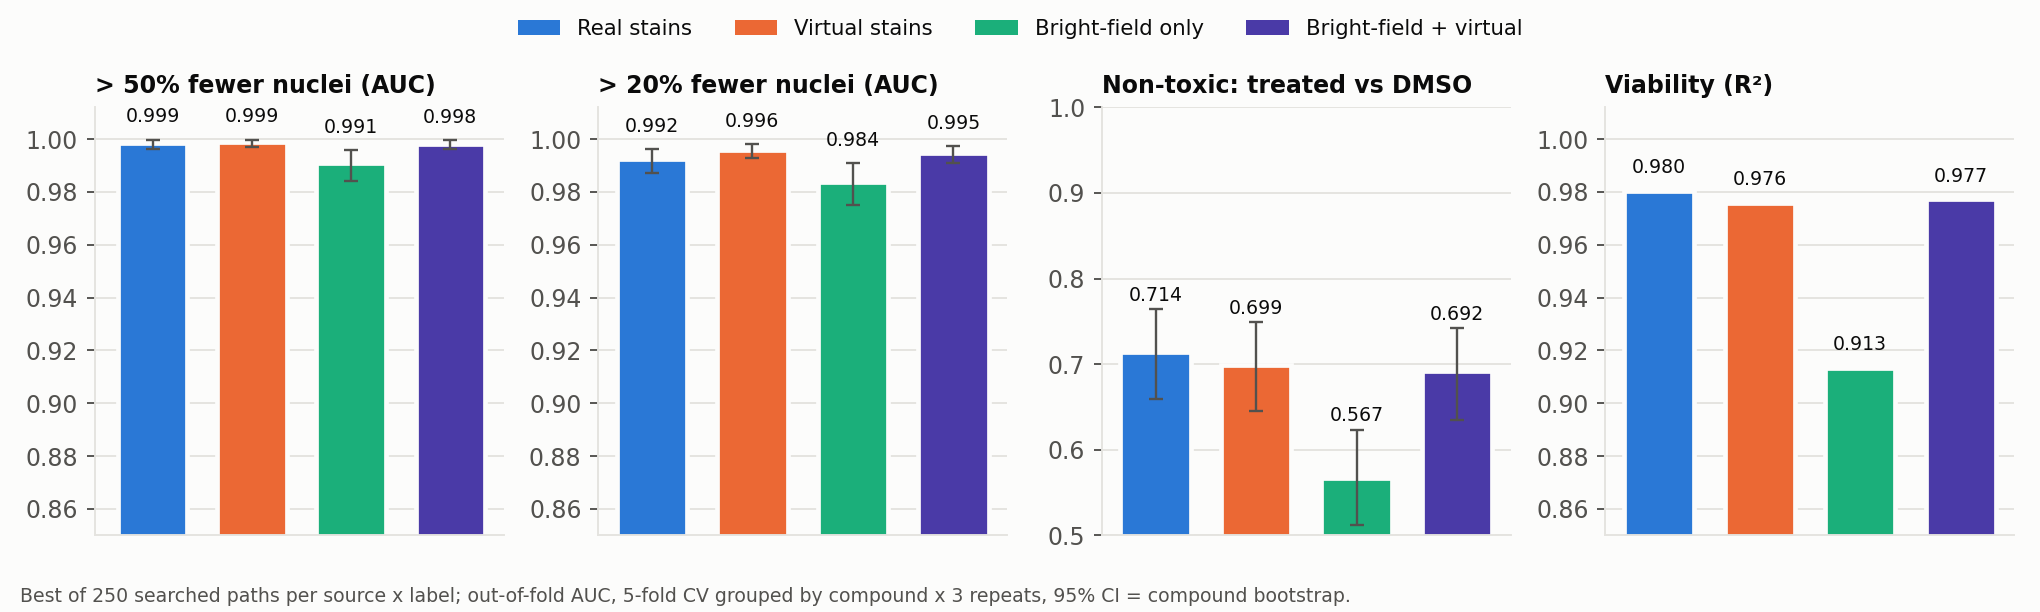

,label,comparison,AUC difference,Holm p,Bayesian P(>0)
0,toxic_0.5,virtual vs brightfield,0.008,0.012,1.000
1,toxic_0.5,virtual vs real,0.000,1,0.638
2,toxic_0.5,brightfield+virtual vs brightfield,0.007,0.012,1.000
3,toxic_0.8,virtual vs brightfield,0.012,0.012,1.000
4,toxic_0.8,virtual vs real,0.004,0.1,0.994
5,toxic_0.8,brightfield+virtual vs brightfield,0.011,0.012,1.000
6,treated_vs_dmso,virtual vs brightfield,0.131,0.00023,1.000
7,treated_vs_dmso,virtual vs real,-0.015,1,0.311
8,treated_vs_dmso,brightfield+virtual vs brightfield,0.125,0.00047,1.000


In [11]:
display(Image("figures/fig_q2_summary.png", width=1100))
q2 = json.load(open("results/a549/q2/q2_report.json"))
pd.DataFrame([{"label": c["label"], "comparison": c["comparison"], "AUC difference": round(c["diff"], 3),
               "Holm p": f"{c['p_holm']:.2g}", "Bayesian P(>0)": round(c["bayes"]["p_gt_0"], 3)} for c in q2["comparisons"]])

## 5. Q3 single cells: same segmentation on real and virtual stains

The winning segmentation path of the Q3 search (Cellpose *cyto3* on all five channels) runs on the real and on the virtual
stains of the fields streamed above; cells are matched by overlap (IoU ≥ 0.5).

segmentation path: {'channels': 'all_five', 'preprocessing': 'none', 'seg_model': 'cellpose_cyto3', 'diameter': '30', 'flow_threshold': '0.4', 'cellprob_threshold': '-1'}


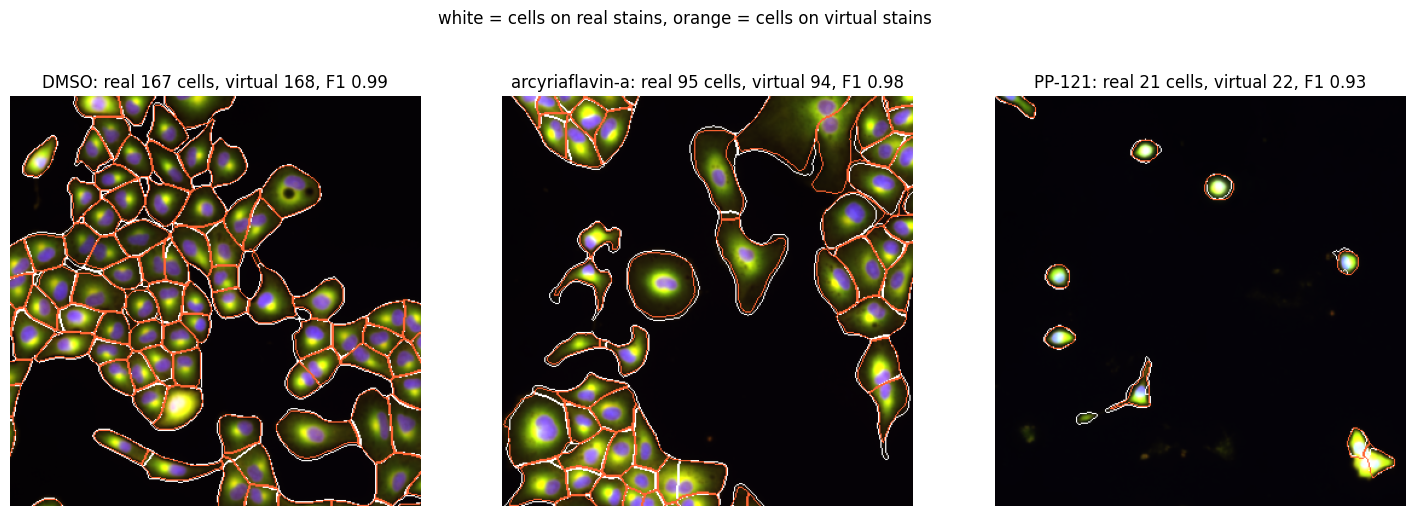

In [12]:
from skimage.segmentation import find_boundaries
from sweep.q3_search import segment
from sweep.q3_single_cell import match
seg = json.load(open("results/a549/q3/seg_fields.json"))["seg_path"]
print("segmentation path:", seg)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (cpd, (real, virt)) in zip(ax, FIELDS.items()):
    mr, mv = segment(real, seg), segment(virt, seg)
    pairs, _ = match(mr, mv)
    f1 = 2 * len(pairs) / max(int(mr.max()) + int(mv.max()), 1)
    rgb = np.stack([np.clip(virt[c] / np.percentile(real[c], 99.7), 0, 1) for c in (3, 1, 0)], -1)
    rgb[find_boundaries(mr, mode="outer")] = (1, 1, 1); rgb[find_boundaries(mv, mode="inner")] = (1, 0.4, 0.2)
    a.imshow(rgb[100:440, 100:440]); a.axis("off")
    a.set_title(f"{cpd}: real {int(mr.max())} cells, virtual {int(mv.max())}, F1 {f1:.2f}")
plt.suptitle("white = cells on real stains, orange = cells on virtual stains"); plt.show()

all 1,536 test fields: F1 0.979, mask AP 0.773, cells per field CCC 0.999, median feature CCC 0.886
cell states: 4 states (morphology > robust_z_vs_dmso > pca > hierarchical_ward > silhouette), real vs virtual ARI 0.745


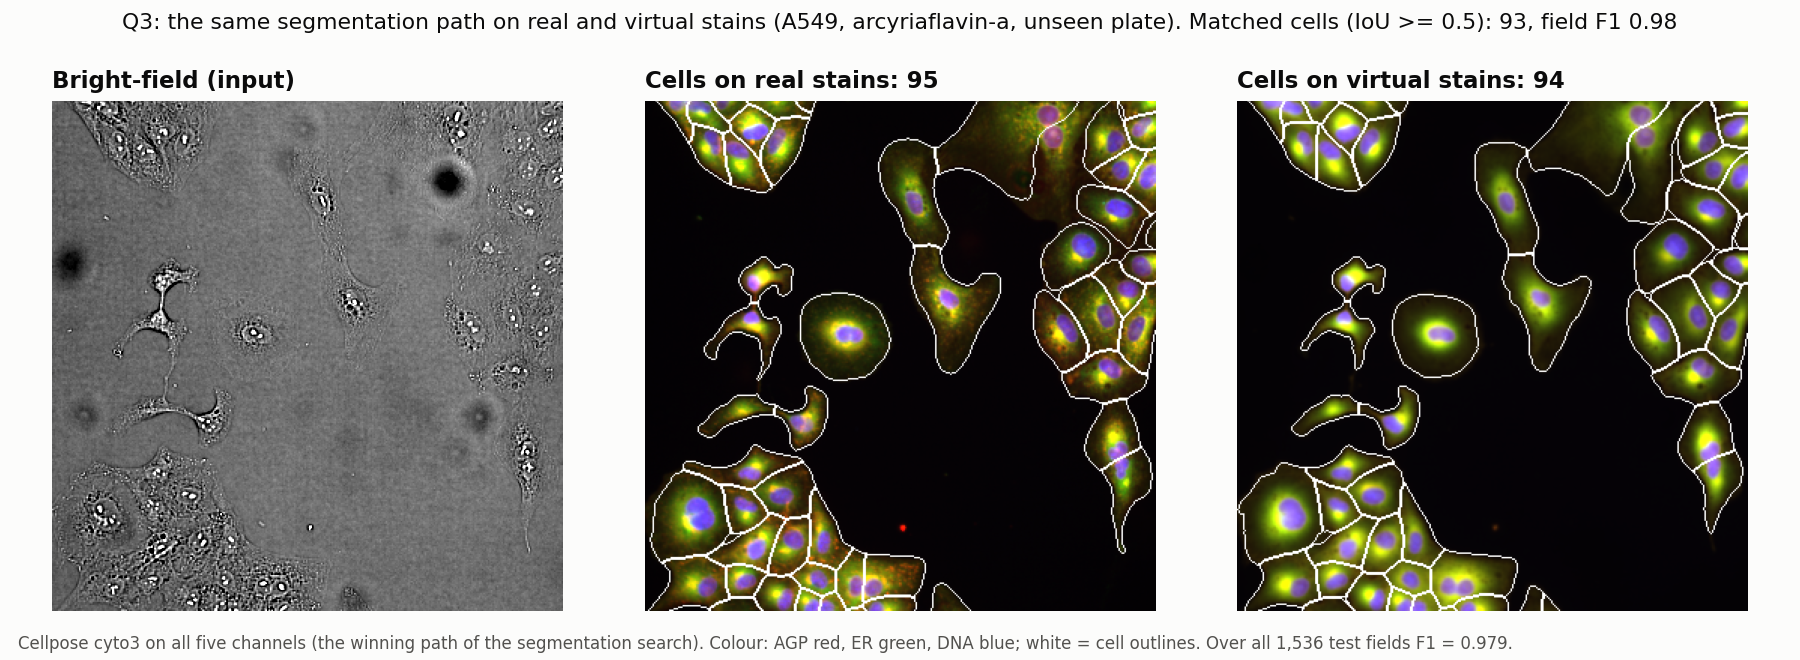

In [13]:
q3 = json.load(open("results/a549/q3/q3_report.json"))
print(f"all 1,536 test fields: F1 {q3['f1']['estimate']:.3f}, mask AP {q3['ap_mean_0.5_0.95']:.3f}, "
      f"cells per field CCC {q3['count_agreement']['lins_ccc']['estimate']:.3f}, median feature CCC {q3['feature_ccc_median']:.3f}")
s = q3["states"]
print(f"cell states: {s['n_states']} states ({' > '.join(s['path'].values())}), real vs virtual ARI {s['ari']:.3f}")
display(Image("figures/fig_q3_example.png", width=1000))

## 6. Q4 chip quality control on real organ-on-a-chip images

3,072 bright-field images of real chips (59 experiments, 6 cell types, good/bad labels; Zenodo 10203721, CC BY 4.0).
A path is `preprocessing → representation (hand-crafted, texture, CNNs, DINOv2, CLIP) → fusion → reduction → model`,
cross-validated by experiment. The image embeddings take a GPU hour to compute (`python -m sweep.q4_chip_qc embed`), so this
section shows the saved search: every path with its scores is in `results/chips/q4/q4_search_paths.csv`.

1003 paths evaluated, 484 reached 100% of the data


,preprocessing,representation,fusion,reduction,model,score_25,score_50,value
729,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865
520,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865
830,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865
829,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865
821,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865
820,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865
819,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865
808,centre_crop,dinov2_small,concat_with_handcrafted,correlation_filter_0.9,logistic_l1,0.813,0.812,0.865


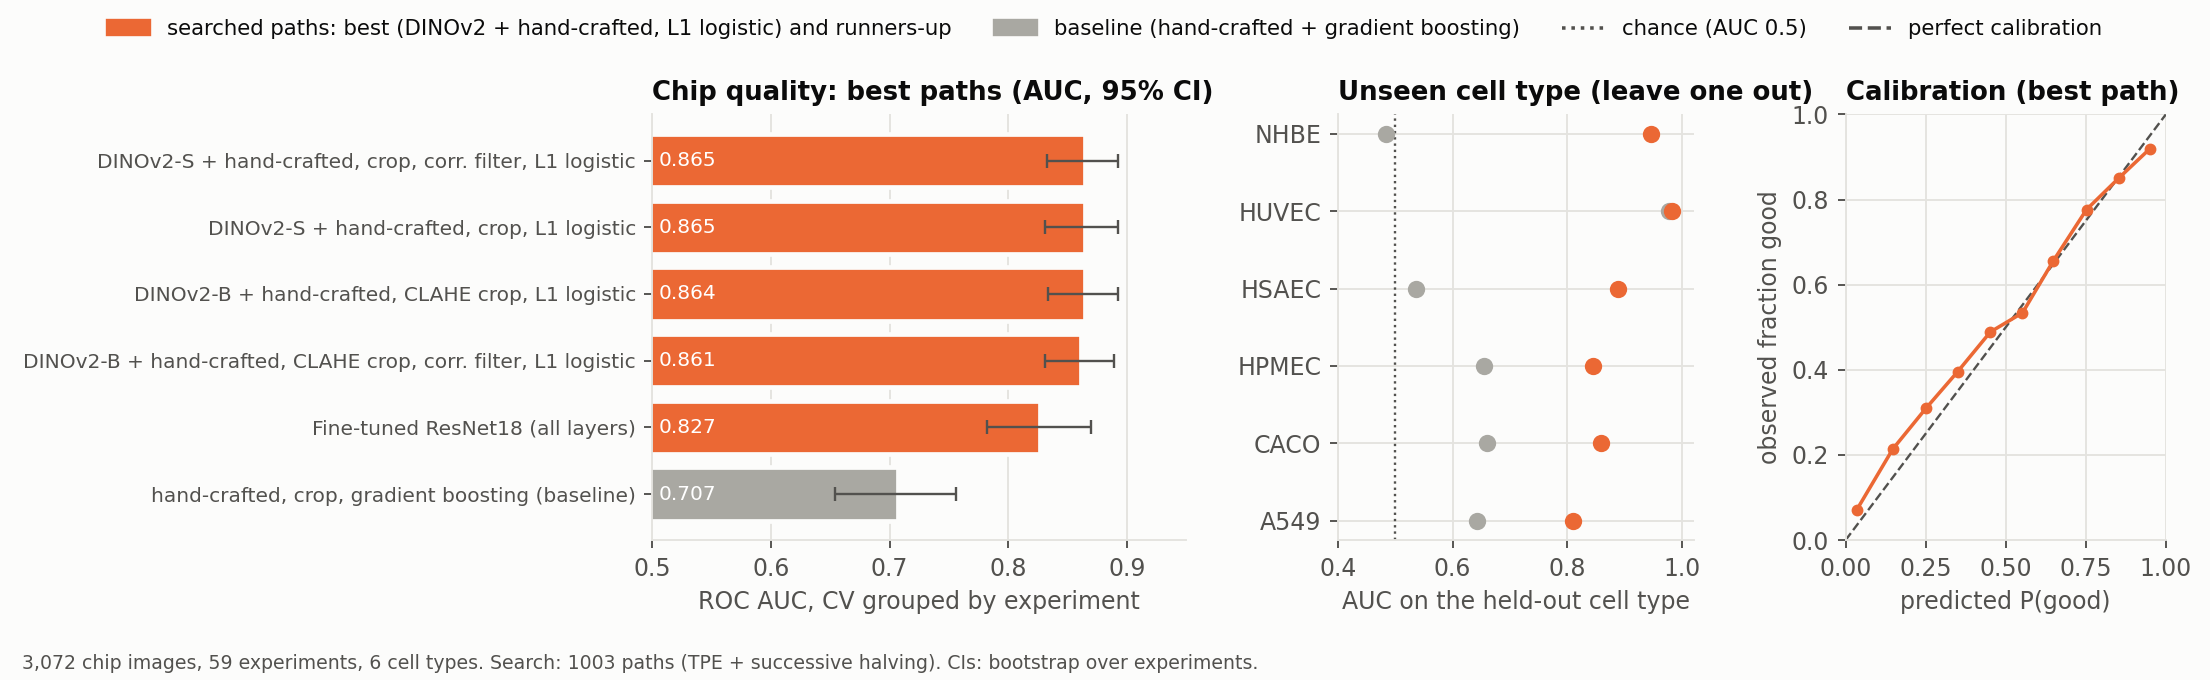

In [14]:
q4p = pd.read_csv("results/chips/q4/q4_search_paths.csv")
done = q4p[(q4p.state == "COMPLETE") & q4p.skipped.isna()].sort_values("value", ascending=False)
print(f"{len(q4p[q4p.skipped.isna()])} paths evaluated, {len(done)} reached 100% of the data")
display(done[["preprocessing", "representation", "fusion", "reduction", "model", "score_25", "score_50", "value"]].head(8).round(3))
display(Image("figures/fig_q4_summary.png", width=1100))

## 7. Replication on a second cell line (U2OS)

The winning paths of the A549 study were applied to U2OS (a separate study; nothing re-chosen): the Q1 winner retrained on U2OS
plate BR00117011 and tested once on BR00117012; the Q2 and Q3 winning pipelines on the U2OS test plate.

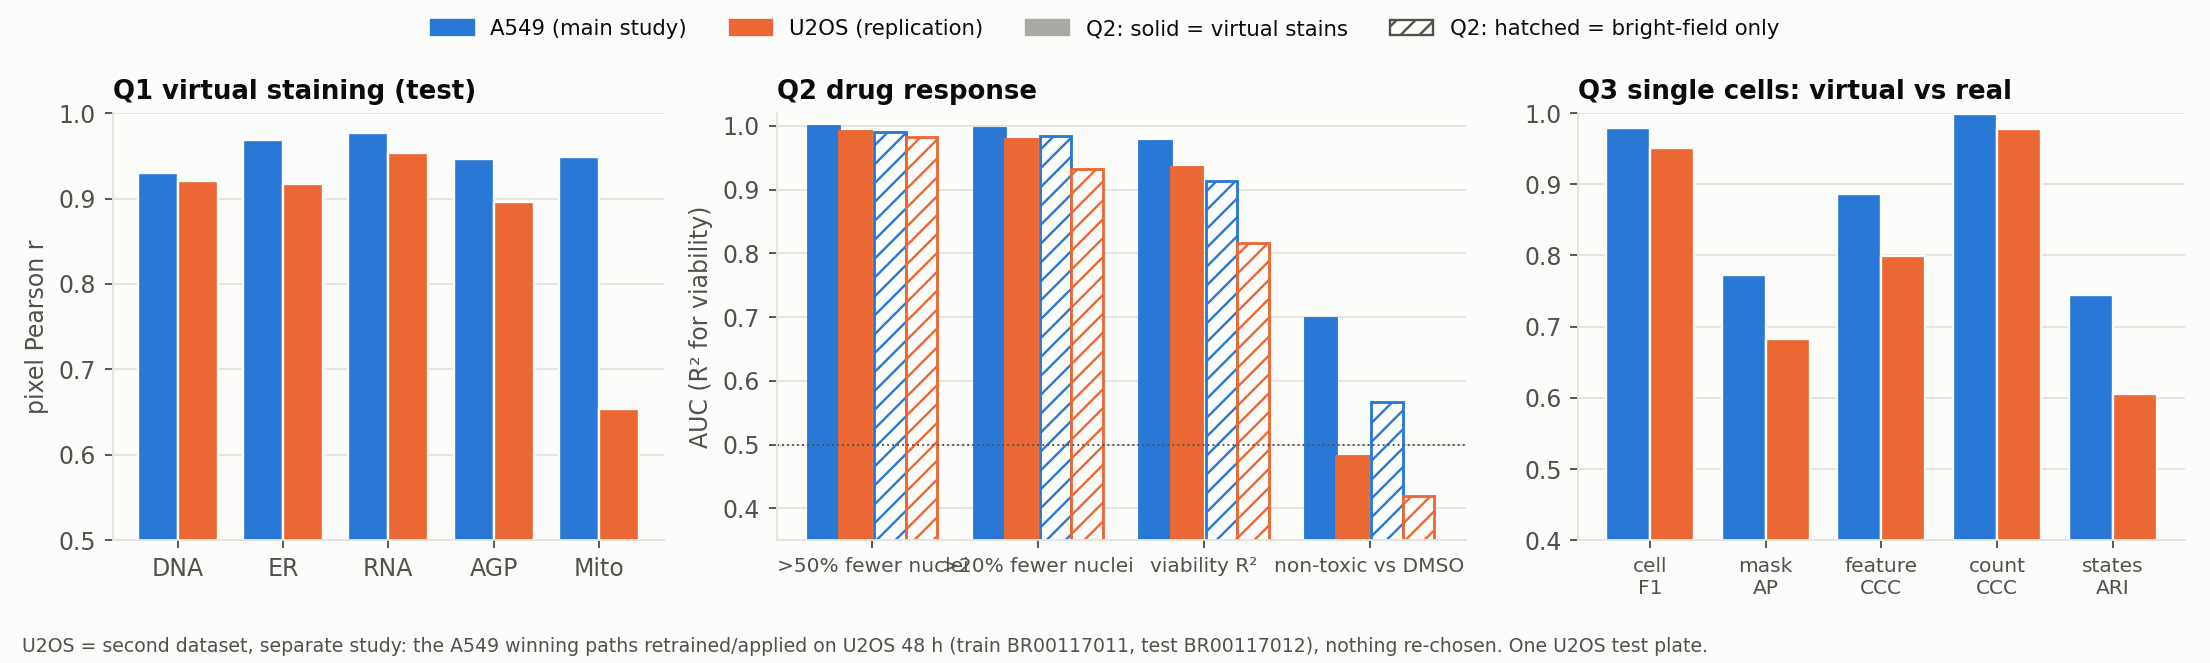

U2OS pixel r (held-out compounds): {'AGP': 0.896, 'DNA': 0.92, 'ER': 0.917, 'Mito': 0.654, 'RNA': 0.953}


In [15]:
display(Image("figures/fig_replication.png", width=1100))
u = json.load(open("results/u2os/q1/report.json"))
print("U2OS pixel r (held-out compounds):", {r["channel"]: r["pearson"] for r in u["pixel"] if r["group"] == "held-out cpds"})

Four stains transfer (r 0.89–0.95); mitochondria do not (0.65). Toxicity results replicate; the subtle drug effect does not
on a single U2OS plate, even with real stains.

## 8. The end-to-end system: images in, all four answers out

`vcp_system.py` puts the final models together: Q1 virtual stains from the bright-field planes, then Q2 (drug response per well)
and Q3 (cells and cell states per field) on the virtual stains, and Q4 (chip quality) on chip photos. The final Q2/Q3 models are
the winning paths fitted on plate BR00117017; here they run on plate **BR00117019, never used to fit any model**. The Q4
examples come from chip experiments held out of the Q4 fit. Real stains are downloaded only as a check column.

Below: PP-121 (cytotoxic), arcyriaflavin-a (changes cells), 3 DMSO controls, one field each, and two held-out chips.

In [16]:
chips = " ".join(sorted(glob.glob("apps/web_demo/examples/chips/*bad.png"))[:1] + sorted(glob.glob("apps/web_demo/examples/chips/*good.png"))[:1])
!python vcp_system.py --plate BR00117019 --wells B16 B04 --dmso 3 --sites 1 --chips {chips} --out {WORK}/report

models loaded (Q1 on cuda, test-time augmentation True)
Q1-Q3: plate BR00117019, wells ['B16', 'B04'] + 3 DMSO wells, fields [1]
  B16 field 1: 19 cells (virtual stains)
  B04 field 1: 81 cells (virtual stains)
  A02 field 1: 206 cells (virtual stains)
  A09 field 1: 103 cells (virtual stains)
  A17 field 1: 109 cells (virtual stains)

Q2 drug response + Q3 cells per well (virtual stains only; (real) = real-stain check):
well        compound kills>50% kills>20%  viability  (real) drug effect*  cells    main state
 B16          PP-121       yes       yes       0.12    0.16      (toxic)     19 small compact
 B04 arcyriaflavin-a       yes       yes       0.43    0.72      (toxic)     81 large compact
 A02            DMSO        no        no       1.13    1.85         0.91    206 large compact
 A09            DMSO        no       yes       0.57    0.88      (toxic)    103 large compact
 A17            DMSO        no        no       0.59    1.00         0.51    109 large compact
* drug-effe

In [17]:
rep = json.load(open(WORK / "report" / "report.json"))
cols = ["well", "compound", "toxic_0.5_call", "toxic_0.8_call", "viability_estimate", "viability_real_stains",
        "treated_vs_dmso_score", "cells_per_field"]
display(pd.DataFrame(rep["wells"])[cols + [c for c in rep["wells"][0] if c.startswith("S")]].round(2))
pd.DataFrame(rep["chips"])

,well,compound,toxic_0.5_call,toxic_0.8_call,viability_estimate,viability_real_stains,treated_vs_dmso_score,cells_per_field,S0 large elongated,S1 small compact,S2 large compact,S3 very large compact
0,B16,PP-121,True,True,0.12,0.16,0.01,19.0,0.05,0.84,0.11,0.00
1,B04,arcyriaflavin-a,True,True,0.43,0.72,0.91,81.0,0.32,0.27,0.41,0.00
2,A02,DMSO,False,False,1.13,1.85,0.91,206.0,0.12,0.43,0.45,0.00
3,A09,DMSO,False,True,0.57,0.88,0.38,103.0,0.14,0.39,0.46,0.02
4,A17,DMSO,False,False,0.59,1.00,0.51,109.0,0.19,0.31,0.49,0.01


,image,p_good
0,apps/web_demo/examples/chips/230320_169_HPMEC_...,0.091609
1,apps/web_demo/examples/chips/221010_80_HUVEC_g...,0.913044


The full report (`report.html`) adds, for every field, the bright-field input, the virtual stains with the Q3 cell outlines,
and the real stains for comparison. Held-out checks of the final models (`models/final_models.json`): Q2 AUC 0.998 / 0.995
(kills > 50% / > 20%), viability R² 0.942, drug effect AUC 0.727 on the plate excluded from the final fit (used earlier to choose the paths); Q3 real vs virtual states ARI 0.714;
Q4 AUC 0.800 on 6 chip experiments excluded from the fit.

## 9. Reproduce the full results

| Step | Command | Hardware / time |
|---|---|---|
| Data | `python download.py` | CPU, ~20 GB, 1 h |
| End-to-end system | `python vcp_system.py --plate BR00117019 --wells ... --chips ...` (final models: `python tools/fit_final_models.py`) | CPU, about 20 s per field |
| Q1 search, final, test | `python -m sweep.q1_translation init/search/final/variants/choose`, `python evaluate.py --winner ...` | GPU (2×T4), ~15 h |
| Q2 | `python -m sweep.q2_search all --features <q1_test>/site_features.csv` | CPU, ~4 h |
| Q3 | `python -m sweep.q3_search predict/segsearch/features/downstream/supervised/assess` | GPU + CPU, ~8 h |
| Q4 | `python -m sweep.q4_chip_qc embed/search/finetune/assess` | GPU + CPU, ~10 h |
| U2OS | `VCP_TRAIN_PLATES=BR00117011 VCP_TEST_PLATES=BR00117012 python -m sweep.q1_translation replicate --winner ...` | GPU, ~3 h |
| Kaggle | `python kaggle_jobs/build.py <job>` then `kaggle kernels push -p kaggle_jobs/kernels/<job>` | free Kaggle GPUs |

Every number in the report comes from `results/` (`results/results.json` collects them).